# 08 · dataset_1000 ile Eğitim ve Değerlendirme (iyileştirilmiş)

`data/dataset_1000`: **1000 target + 1000 notarget** RD haritası (195 ses dosyası, 14 ses klasörü; kaynaklar `kaynaklar.csv`).
Notebook 07'ye (dataset_500) göre değişenler:

1. **Veri:** hedef SNR aralığı yükseltildi (giriş −38…−20 dB → hedeflerin ~%75'i belirgin), veri 2 katı.
2. **Karar eşiği:** 0.5 yerine **val setinde yanlış alarm oranını `TARGET_PFA` ile sınırlayan** eşik seçilir (CFAR mantığı).
3. **Augmentation (yalnızca train):** Doppler aynalama + dairesel Doppler kaydırma — hedefin varlığı değişmez.
   **Weight decay** ve daha uzun sabır.
4. Haritalar 0–40 dB aralığında çizilir (ECA çentiğindeki çok düşük değerler renk skalasını bozmaz).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "passive_radar").is_dir())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import json
from dataclasses import asdict, replace
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from passive_radar.config import CLASS_NAMES, ProjectConfig
from passive_radar.data.dataset import RangeDopplerDataset, make_data_loader
from passive_radar.data.indexing import SPLIT_NAMES, assert_no_group_leakage, records_in_split, save_split_csv, split_by_source
from passive_radar.data.rd_dataset import load_rd_dataset_config, load_rd_samples, samples_to_records
from passive_radar.data.transforms import doppler_augment
from passive_radar.evaluation.metrics import collect_predictions, compute_classification_metrics
from passive_radar.evaluation.plots import plot_confusion_matrix, plot_rd_maps, plot_training_history
from passive_radar.models.checkpoint import load_checkpoint
from passive_radar.models.cnn import RangeDopplerCNN, count_trainable_parameters
from passive_radar.training.runtime import resolve_device, set_seed
from passive_radar.training.trainer import Trainer

DATASET_NAME = "dataset_1000"
TARGET_PFA = 0.10          # val setinde izin verilen yanlış alarm oranı
GROUP_BY = "source_file"   # daha katı: "source_group" (bütün ses klasörü dışarıda)

config = ProjectConfig.default(PROJECT_ROOT)
paths = config.paths
data_dir = paths.data_dir / DATASET_NAME
out_dir = paths.outputs_dir / DATASET_NAME
checkpoint_path = paths.models_dir / f"{DATASET_NAME}_best_model.pt"
(out_dir / "figures").mkdir(parents=True, exist_ok=True)

sim = load_rd_dataset_config(data_dir)
max_range_km = sim["r_max"] * sim["range_cell_m"] / 1e3
max_doppler_hz = sim["fD_max"]
DYN_DB = 40.0

rd_config = config.rd_map
model_config = replace(config.model, in_channels=rd_config.num_channels, pooled_size=(2, 2), global_pool="max")
training_config = replace(config.training, batch_size=32, learning_rate=1e-3, weight_decay=1e-4,
                          max_epochs=40, early_stopping_patience=8)
for name, section in (("rd_map", rd_config), ("model", model_config), ("training", training_config)):
    print(f"{name}: {asdict(section)}")
print(f"map: {sim['n_doppler']} Doppler x {sim['r_max']} range | {max_range_km:.1f} km, ±{max_doppler_hz:.0f} Hz")


def show_maps(rows, titles, save_name):
    """Haritaları 0..DYN_DB dB aralığında çiz (npy satır 0 = +Doppler -> origin='lower' için çevrilir)."""
    maps = [np.clip(np.flipud(np.load(p).astype(np.float32)), 0, DYN_DB) for p in rows["path"]]
    markers = [(r, d) if l == 1 else None for l, r, d in rows[["label", "bistatic_range_km", "doppler_hz"]].itertuples(index=False)]
    plot_rd_maps(maps, titles, max_range_km, max_doppler_hz, markers=markers, save_path=out_dir / "figures" / save_name)
    plt.show()

rd_map: {'dynamic_range_db': 40.0}
model: {'in_channels': 1, 'num_classes': 2, 'conv_channels': (16, 32, 64, 128), 'kernel_size': 3, 'pooled_size': (2, 2), 'global_pool': 'max', 'hidden_units': 128, 'dropout': 0.4}
training: {'batch_size': 32, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'max_epochs': 40, 'early_stopping_patience': 8, 'min_delta': 0.0001, 'num_workers': 0, 'device': 'auto', 'seed': 42, 'cache_images': True}
map: 371 Doppler x 73 range | 99.3 km, ±185 Hz


## 1. Veri ve ses dosyası bazlı bölme

In [3]:
samples = load_rd_samples(data_dir)
meta = pd.DataFrame([s.__dict__ for s in samples])
meta["path"] = [str(s.path(data_dir)) for s in samples]

records = samples_to_records(samples, data_dir, group_by=GROUP_BY)
assigned = split_by_source(records, replace(config.split, max_holdout_group_fraction=0.2))
assert_no_group_leakage(assigned)
save_split_csv(assigned, out_dir / "splits.csv", relative_to=paths.project_root)
meta["split"] = meta["path"].map({str(r.path): r.split for r in assigned})

pd.DataFrame([
    {"split": s, "maps": len(rs), "target": sum(r.label == 1 for r in rs),
     "visible_targets": int(meta.loc[(meta.split == s) & (meta.label == 1), "visible"].sum()),
     "audio_files": len({r.source_id for r in rs}),
     "audio_folders": meta.loc[meta.split == s, "source_group"].nunique()}
    for s in SPLIT_NAMES for rs in [records_in_split(assigned, s)]
])

,split,maps,target,visible_targets,audio_files,audio_folders
0,train,1434,718,525,140,14
1,val,295,150,119,28,13
2,test,271,132,103,27,13


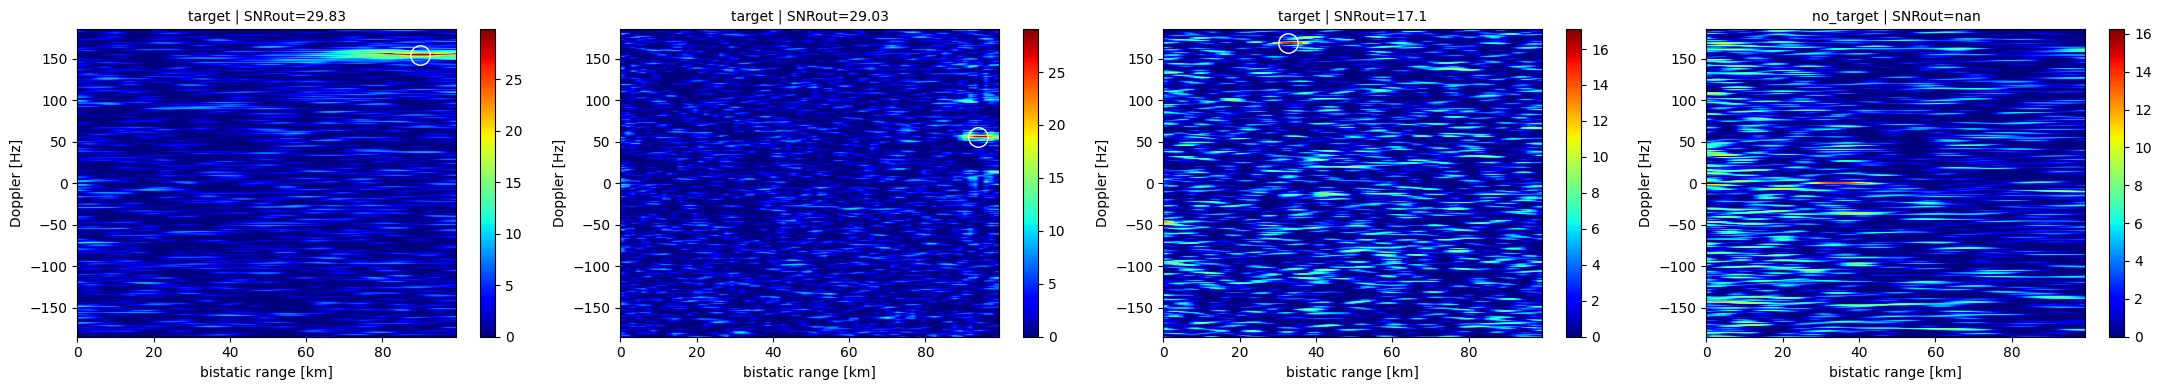

In [4]:
show = pd.concat([meta[meta.label == 1].sort_values("snr_out_db", ascending=False).head(2),
                  meta[meta.label == 1].sort_values("snr_out_db").iloc[[len(meta) // 4]],
                  meta[meta.label == 0].head(1)])
show_maps(show, [f"{CLASS_NAMES[l]} | SNRout={s}" for l, s in show[["label", "snr_out_db"]].itertuples(index=False)],
          "examples.png")

## 2. Eğitim (augmentation yalnızca train; en iyi model val kaybına göre)

device: mps | parameters: 163,314
epoch 01 | train_loss 0.7240 | val_loss 0.7876 | val_acc 0.492 | val_f1 0.000 *best*
epoch 02 | train_loss 0.6515 | val_loss 0.6195 | val_acc 0.688 | val_f1 0.681 *best*
epoch 03 | train_loss 0.6084 | val_loss 0.5709 | val_acc 0.725 | val_f1 0.664 *best*
epoch 04 | train_loss 0.5876 | val_loss 0.5671 | val_acc 0.624 | val_f1 0.652 *best*
epoch 05 | train_loss 0.5547 | val_loss 0.4863 | val_acc 0.800 | val_f1 0.779 *best*
epoch 06 | train_loss 0.5291 | val_loss 0.5158 | val_acc 0.763 | val_f1 0.748
epoch 07 | train_loss 0.5223 | val_loss 0.5166 | val_acc 0.769 | val_f1 0.724
epoch 08 | train_loss 0.5026 | val_loss 0.4170 | val_acc 0.800 | val_f1 0.803 *best*
epoch 09 | train_loss 0.4937 | val_loss 0.4441 | val_acc 0.769 | val_f1 0.730
epoch 10 | train_loss 0.5027 | val_loss 0.4169 | val_acc 0.786 | val_f1 0.777 *best*
epoch 11 | train_loss 0.4734 | val_loss 0.4779 | val_acc 0.756 | val_f1 0.707
epoch 12 | train_loss 0.4739 | val_loss 0.4767 | val_acc 0.

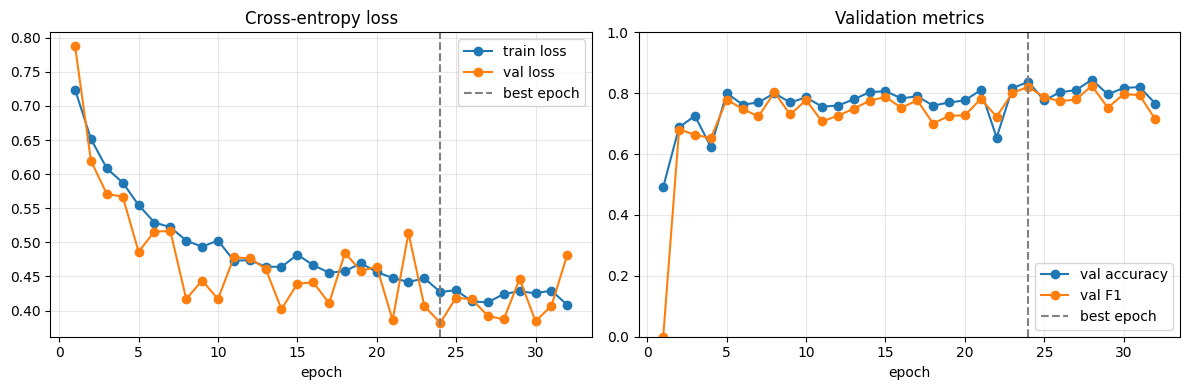

In [5]:
augment = partial(doppler_augment, max_shift=40)
loaders = {
    split: make_data_loader(
        RangeDopplerDataset(records_in_split(assigned, split), rd_config, cache_images=True,
                            augment=augment if split == "train" else None, seed=training_config.seed),
        training_config.batch_size, shuffle=(split == "train"), seed=training_config.seed)
    for split in SPLIT_NAMES
}
set_seed(training_config.seed)
device = resolve_device(training_config.device)
model = RangeDopplerCNN(model_config)
print("device:", device, "| parameters:", f"{count_trainable_parameters(model):,}")

trainer = Trainer(model, training_config, device, checkpoint_path, CLASS_NAMES, rd_config)
history = trainer.fit(loaders["train"], loaders["val"])
history.save_json(out_dir / "training_history.json")
plot_training_history(history, save_path=out_dir / "figures" / "training_history.png")
plt.show()

## 3. Karar eşiği (val) ve test değerlendirmesi

Eşik **yalnızca val** setinden seçilir: hedefsiz val haritalarının en fazla `TARGET_PFA` kadarı eşiği aşar.
Test seti eşik seçiminde hiç kullanılmaz.

In [6]:
checkpoint = load_checkpoint(checkpoint_path, device=device)
preds = {split: collect_predictions(checkpoint.model, loaders[split], device) for split in ("val", "test")}

val = preds["val"]
threshold = float(np.quantile(val.positive_probability[val.y_true == 0], 1.0 - TARGET_PFA))
print(f"seçilen eşik (val, Pfa <= {TARGET_PFA:.0%}): {threshold:.3f}")

def metrics_at(p, thr):
    y_pred = (p.positive_probability >= thr).astype(int)
    m = compute_classification_metrics(p.y_true, y_pred, p.positive_probability)
    m["false_alarm_rate"] = float(y_pred[p.y_true == 0].mean())
    m["detection_rate"] = float(y_pred[p.y_true == 1].mean())
    return m

results = {f"{s} @ {name}": metrics_at(preds[s], thr)
           for s in ("val", "test") for name, thr in (("0.5", 0.5), ("eşik", threshold))}
(out_dir / "test_metrics.json").write_text(json.dumps({"threshold": threshold, **results}, indent=2))
pd.DataFrame({k: {m: v for m, v in d.items() if m != "confusion_matrix"} for k, d in results.items()}).T.round(3)

seçilen eşik (val, Pfa <= 10%): 0.479


,accuracy,precision,recall,f1,support,roc_auc,false_alarm_rate,detection_rate
val @ 0.5,0.837,0.932,0.733,0.821,295.0,0.906,0.055,0.733
val @ eşik,0.834,0.885,0.773,0.826,295.0,0.906,0.103,0.773
test @ 0.5,0.823,0.856,0.765,0.808,271.0,0.866,0.122,0.765
test @ eşik,0.775,0.763,0.780,0.772,271.0,0.866,0.230,0.780


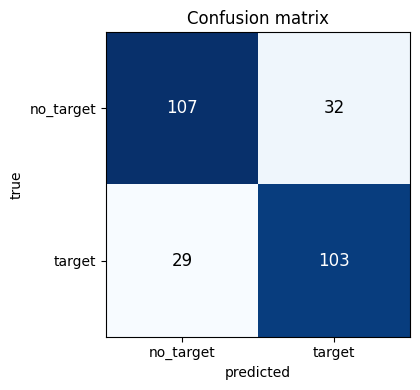

In [7]:
plot_confusion_matrix(results["test @ eşik"]["confusion_matrix"], CLASS_NAMES,
                      save_path=out_dir / "figures" / "confusion_matrix_test.png")
plt.show()

## 4. Tespit olasılığı — çıkış SNR'ına göre (test, seçilen eşikte)

false alarm rate (test): 0.230
detection rate, visible targets (SNRout >= 13 dB): 0.922
detection rate, weak targets    (SNRout <  13 dB): 0.276


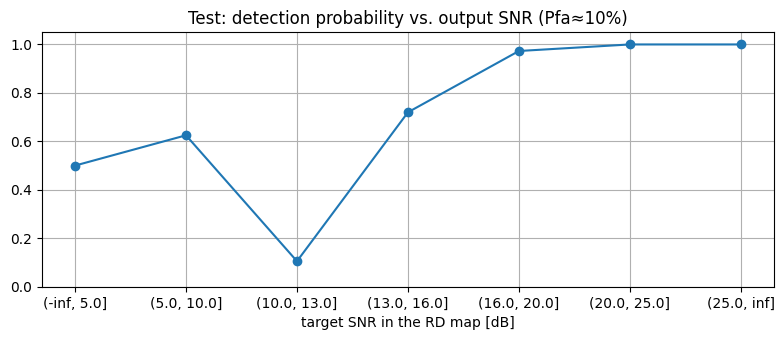

,detection_probability,maps
snr_bin,,
"(-inf, 5.0]",0.500000,2
"(5.0, 10.0]",0.625000,8
"(10.0, 13.0]",0.105263,19
"(13.0, 16.0]",0.720000,25
"(16.0, 20.0]",0.972973,37
"(20.0, 25.0]",1.000000,29
"(25.0, inf]",1.000000,12


In [8]:
test_records = records_in_split(assigned, "test")
tp = preds["test"]
frame = pd.DataFrame({"path": [str(r.path) for r in test_records], "true": tp.y_true,
                      "p_target": tp.positive_probability,
                      "pred": (tp.positive_probability >= threshold).astype(int)}).merge(meta, on="path")

targets = frame[frame["true"] == 1].copy()
targets["snr_bin"] = pd.cut(targets["snr_out_db"], bins=[-np.inf, 5, 10, 13, 16, 20, 25, np.inf])
pd_by_snr = targets.groupby("snr_bin", observed=True)["pred"].agg(detection_probability="mean", maps="size")
print(f"false alarm rate (test): {(frame.loc[frame.true == 0, 'pred'] == 1).mean():.3f}")
print(f"detection rate, visible targets (SNRout >= 13 dB): {targets.loc[targets.visible == True, 'pred'].mean():.3f}")
print(f"detection rate, weak targets    (SNRout <  13 dB): {targets.loc[targets.visible == False, 'pred'].mean():.3f}")

axis = pd_by_snr["detection_probability"].plot(marker="o", figsize=(8, 3.5), ylim=(0, 1.05), grid=True,
                                                title=f"Test: detection probability vs. output SNR (Pfa≈{TARGET_PFA:.0%})")
axis.set_xlabel("target SNR in the RD map [dB]")
plt.tight_layout()
plt.savefig(out_dir / "figures" / "detection_vs_snr.png", dpi=120)
plt.show()
pd_by_snr

In [9]:
# Ses klasörüne göre doğruluk (klasör başına örnek sayısı az; dikkatli yorumlanmalı)
frame.assign(correct=frame.true == frame.pred).groupby("source_group")["correct"].agg(["mean", "size"]).sort_values("mean")

,mean,size
source_group,,
İSTEK ÜZERİNE DAHA UZUN İNCE BİR YOL ¦ DRIVE BEYOND HORIZONS ¦ BÖLÜM 3 (128kbit_AAC),0.619048,21
"1 hour fighter jet sound (jet engine, stealth bomber, f16, f117, f117a, raptor, b2, ASMR) (128kbit_AAC)",0.650000,20
Nervous System Reset ¦ 75Hz + 111Hz Emotional Balance ¦ Healing Bowls ¦ Meditation & Sleep Music (128kbit_AAC),0.684211,19
Top hits 2024 playlist ~ Trending music 2024 ~ Best songs 2024 updated weekly (Playlist Hits) (128kbit_AAC),0.700000,20
ÇİLEKEŞLER - DRIVE BEYOND HORIZONS ¦ FİNAL (128kbit_AAC),0.722222,18
RRaenee GTA 5 PLAYLİST Editimi İzliyor! (Komik Anlar) (128kbit_AAC),0.727273,11
ZOMBİLERİN YIKMAYA KIYAMAYACAĞI EV! ¦ 7 DAYS TO DIE ¦ S3 B4 (128kbit_AAC),0.761905,21
"90min of PURE RAW RACING SOUNDS ¦ F1, Group C, GT1, GT2, GT3, Rally, DTM, Classics, ... (128kbit_AAC)",0.781250,32
"963 Hz Frequency of God, Return to Oneness, Spiritual Connection, Crown Chakra, Meditation Music (128kbit_AAC)",0.842105,19


## 5. Hatalı sınıflandırılan örnekler

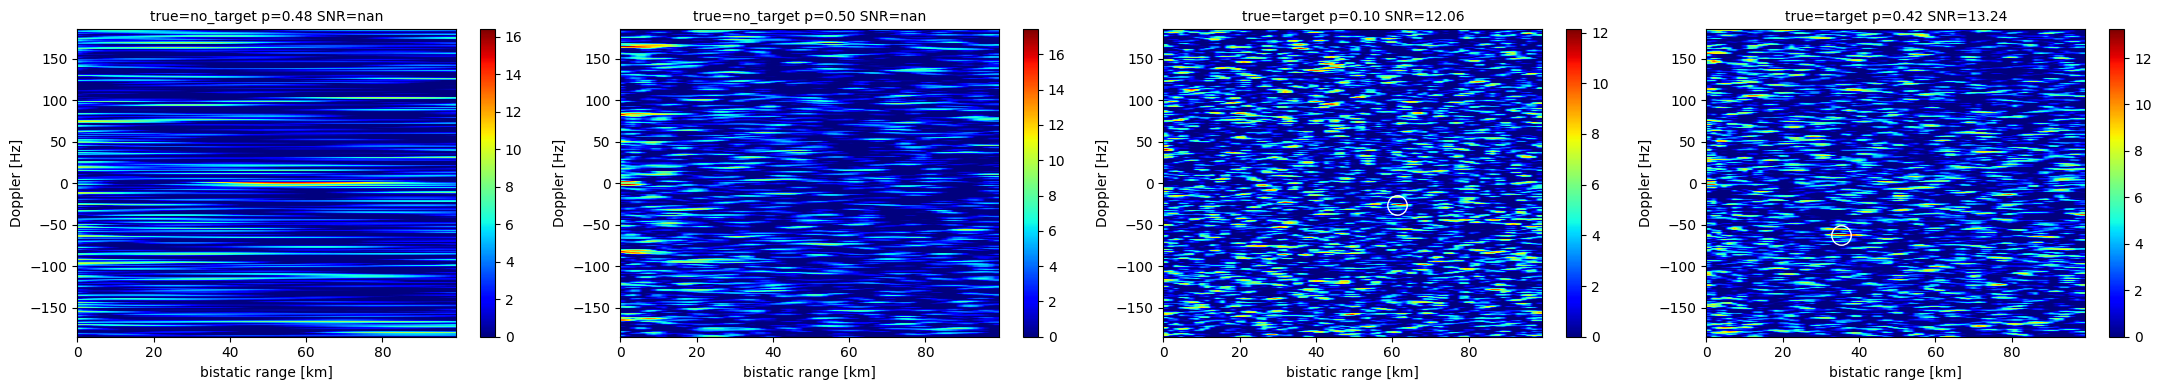

In [10]:
wrong = pd.concat([frame[(frame.true == 0) & (frame.pred == 1)].head(2),
                   frame[(frame.true == 1) & (frame.pred == 0)].head(2)])
if wrong.empty:
    print("No misclassified test maps.")
else:
    show_maps(wrong, [f"true={CLASS_NAMES[t]} p={q:.2f} SNR={s}" for t, q, s in
                      wrong[["true", "p_target", "snr_out_db"]].itertuples(index=False)], "misclassified_test.png")

## 6. Yorum ve sınırlılıklar

* Etiketler fiziksel olarak tanımlıdır (yankı eklendi / eklenmedi); kaynak ses ve zaman aralığı `kaynaklar.csv`'de.
* Eşik val setinde sabit yanlış alarm oranına göre seçildi; test sonuçları bu eşikte raporlanır.
* Augmentation yalnızca Doppler ekseninde (aynalama + kaydırma); range ekseni ve kısa menzildeki ECA çentiği korunur.
* Bölme ses dosyası bazındadır; içerik türüne genelleme için `GROUP_BY = "source_group"` ile tekrar çalıştırılabilir.
* Gerçek ölçüm verisine genelleme doğrulanmamıştır.

Doğruluk: 89.5%  (19 parça)


,zaman_s,gercek,menzil_km,doppler_hz,snr_out_db,p_target,model_karari,dogru_mu
0,0.0-0.5,HEDEF,72.1,-111.5,20.6,0.998,HEDEF VAR,✓
1,0.5-1.0,yok,NaN,NaN,NaN,0.260,hedef yok,✓
2,1.0-1.5,yok,NaN,NaN,NaN,0.117,hedef yok,✓
3,1.5-2.0,HEDEF,36.7,-155.6,15.4,0.706,HEDEF VAR,✓
4,2.0-2.5,HEDEF,44.9,162.0,8.5,0.175,hedef yok,✗
5,2.5-3.0,HEDEF,54.4,65.0,24.8,1.000,HEDEF VAR,✓
6,3.0-3.5,yok,NaN,NaN,NaN,0.046,hedef yok,✓
7,3.5-4.0,HEDEF,78.9,161.7,27.8,1.000,HEDEF VAR,✓
8,4.0-4.5,HEDEF,85.7,99.5,22.6,0.997,HEDEF VAR,✓
9,4.5-5.0,yok,NaN,NaN,NaN,0.428,hedef yok,✓


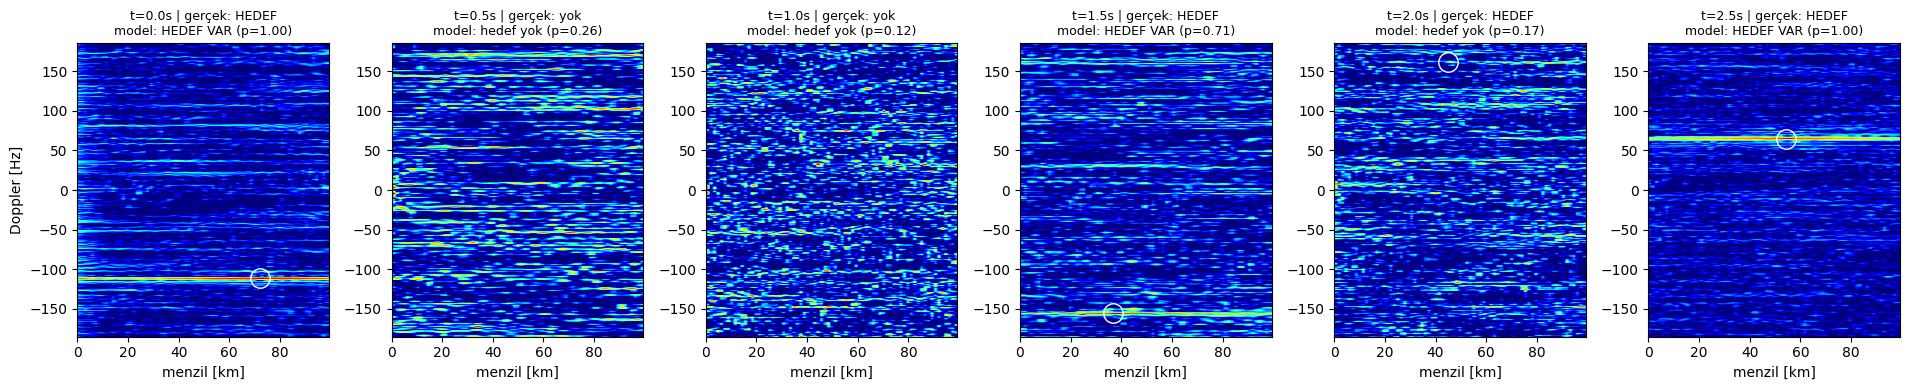

In [2]:
# ================== AYARLAR ==================
AUDIO_PATH = "/Users/iremnuryilmaz/Desktop/Projects/Capstone_Project/Capstone-Project/data/music/kus_sesi_10sn.mp3"   # <-- ses dosyanın yolu
TARGET     = "random"   # "random" (%50 hedef), "always" (her parçada hedef), "none" (hiç hedef yok)
SEGMENTS   = 0         # kaç adet 0.5 s'lik parça işlensin (0 = dosyanın tamamı)
START_S    = 0.0        # kaçıncı saniyeden başlasın
THRESHOLD  = 0.5        # p_target >= eşik  ->  "HEDEF VAR"
SEED = None      # None = her çalıştırmada farklı senaryo; sabit sayı (örn. 0) = tekrarlanabilir
# Hedefin yerini sen belirlemek istersen (None = rastgele):
RANGE_KM, DOPPLER_HZ, SNR_DB = None, None, None   # örn. 40, -80, -28
# =============================================

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "passive_radar").is_dir())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from passive_radar.simulation.audio_rd import TargetSpec, audio_to_rd_maps, load_sim_config
from passive_radar.data.transforms import rd_map_to_tensor
from passive_radar.models.checkpoint import load_checkpoint
from passive_radar.training.runtime import resolve_device

# 1) Eğitilmiş model ve veri setiyle aynı simülasyon parametreleri
sim_cfg = load_sim_config(PROJECT_ROOT / "data" / "dataset_1000")
device = resolve_device("auto")
ckpt = load_checkpoint(PROJECT_ROOT / "models" / "dataset_1000_best_model.pt", device=device)
model = ckpt.model.eval()

# 2) Ses -> FM yayını -> gözetim kanalı (+/- hedef) -> RD haritaları
segs = audio_to_rd_maps(AUDIO_PATH, sim_cfg, target=TARGET,
                        target_spec=TargetSpec(RANGE_KM, DOPPLER_HZ, SNR_DB),
                        max_segments=SEGMENTS or None, start_s=START_S, seed=0)
assert segs, "İşlenecek (sessiz olmayan) parça bulunamadı."

# 3) Model kararı
with torch.no_grad():
    batch = torch.stack([rd_map_to_tensor(s.db_map, ckpt.preprocessing_config) for s in segs]).to(device)
    p_target = torch.softmax(model(batch), dim=1)[:, 1].cpu().numpy()

# 4) Sonuç tablosu: model kararı vs. gerçek (simülasyonda eklenen) durum
result = pd.DataFrame({
    "zaman_s": [f"{s.t_start_s:.1f}-{s.t_end_s:.1f}" for s in segs],
    "gercek": ["HEDEF" if s.has_target else "yok" for s in segs],
    "menzil_km": [round(s.range_km, 1) if s.has_target else None for s in segs],
    "doppler_hz": [round(s.doppler_hz, 1) if s.has_target else None for s in segs],
    "snr_out_db": [round(s.snr_out_db, 1) if s.has_target else None for s in segs],
    "p_target": p_target.round(3),
    "model_karari": np.where(p_target >= THRESHOLD, "HEDEF VAR", "hedef yok"),
})
result["dogru_mu"] = np.where((p_target >= THRESHOLD) == np.array([s.has_target for s in segs]), "✓", "✗")
print(f"Doğruluk: {(result.dogru_mu == '✓').mean():.1%}  ({len(result)} parça)")
display(result)

# 5) İlk 6 haritanın çizimi (beyaz daire = eklenen hedefin gerçek yeri)
k = min(6, len(segs))
fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 4), squeeze=False)
ext = (0, sim_cfg["r_max"] * sim_cfg["range_cell_m"] / 1e3, -sim_cfg["fD_max"], sim_cfg["fD_max"])
for ax, s, p in zip(axes.flat, segs[:k], p_target[:k]):
    ax.imshow(np.clip(s.db_map.astype(np.float32), 0, 40), aspect="auto", extent=ext, cmap="jet")
    if s.has_target:
        ax.plot(s.range_km, s.doppler_hz, "o", ms=14, mfc="none", mec="white")
    ax.set_title(f"t={s.t_start_s:.1f}s | gerçek: {'HEDEF' if s.has_target else 'yok'}\n"
                 f"model: {'HEDEF VAR' if p >= THRESHOLD else 'hedef yok'} (p={p:.2f})", fontsize=9)
    ax.set_xlabel("menzil [km]")
axes.flat[0].set_ylabel("Doppler [Hz]")
plt.tight_layout()
plt.show()